In [ ]:
#Install Dependencies
!pip install ultralytics
!pip install roboflow

In [ ]:
#Import Libraries
from ultralytics import YOLO

import cv2
import numpy as np
import matplotlib.pyplot as plt

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
#Download Dataset
import os
from roboflow import Roboflow

# ==== Configuration ====
# Roboflow API key — never hardcode this.
# In Colab: store it once via the "Secrets" tab (key icon in left sidebar),
# name it ROBOFLOW_API_KEY, and enable notebook access.
from google.colab import userdata
ROBOFLOW_API_KEY = userdata.get("ROBOFLOW_API_KEY")

rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace("maulis-workspace-l7bbl").project("fruit_detection-rdzge")
dataset = project.version(1).download("yolov8")

# dataset.location gives the actual download path — use this everywhere
# instead of hardcoding "/content/Fruit_detection-1"
DATASET_BASE_PATH = dataset.location
DATA_YAML_PATH = f"{DATASET_BASE_PATH}/data.yaml"
TEST_IMAGES_GLOB = f"{DATASET_BASE_PATH}/test/images/*"

# Trained model weights (populated after training completes)
BEST_WEIGHTS_PATH = "/content/runs/segment/train/weights/best.pt"
TRAINING_RESULTS_PLOT = "/content/runs/segment/train/results.png"

# Single sample image reused across qualitative prediction cells
SAMPLE_IMAGE_PATH = "UPLOAD YOUR SAMPLE IMAGE PATH HERE" #You can upload and use any sample image here for analysis

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Fruit_detection-1 in yolov8:: 100%|██████████| 2004/2004 [00:00<00:00, 7935.65it/s]


In [ ]:
#Verify the dataset
!ls /content

print(dataset.location)

Fruit_detection-1  sample_data
/content/Fruit_detection-1


In [ ]:
#Load YOLOv8-Seg
model = YOLO("yolov8n-seg.pt")

In [ ]:
!ls DATASET_BASE_PATH

data.yaml  README.roboflow.txt	test  train  valid


In [ ]:
#Training the dataset
results = model.train(
    data=DATA_YAML_PATH,
    epochs=10,
    imgsz=640,
    batch=8,
    device=0
)

Ultralytics 8.4.90 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Fruit_detection-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, p

In [ ]:
metrics = model.val(
    data=DATA_YAML_PATH,
    split="test"
)

Ultralytics 8.4.90 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 86 layers, 3,258,649 parameters, 0 gradients, 11.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1389.9±392.7 MB/s, size: 41.8 KB)
val: Scanning /content/Fruit_detection-1/test/labels... 45 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 45/45 1.6Kit/s 0.0s
val: New cache created: /content/Fruit_detection-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.5s/it 4.6s
                   all         45         71      0.767      0.665      0.736      0.486      0.757      0.655       0.71      0.479
 Anthracnose Fruit Rot          7         12      0.875      0.581      0.721      0.382      0.875      0.582      0.664        0.4
             Gray Mold         28         30      0.822      0.967      0.956        0.7      0.793      0.933 

In [ ]:
from ultralytics import YOLO

model = YOLO(
    BEST_WEIGHTS_PATH
)

results = model.predict(
    source=SAMPLE_IMAGE_PATH, #Use any sample image
    conf=0.25,
    save=True
)


image 1/1 /content/strawberry.jpeg: 448x640 3 Anthracnose Fruit Rots, 11.3ms
Speed: 2.5ms preprocess, 11.3ms inference, 2.0ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/segment/predict-2


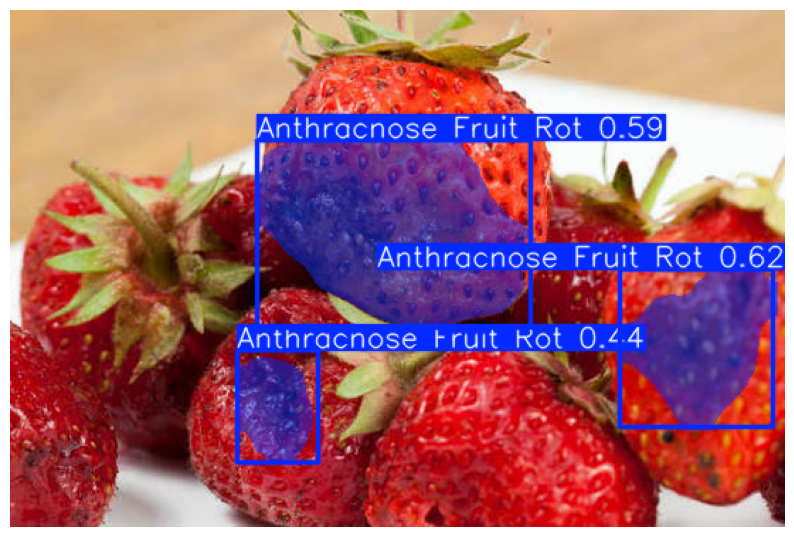

In [ ]:
import matplotlib.pyplot as plt
import cv2

img = results[0].plot()

plt.figure(figsize=(10,10))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [ ]:
metrics = model.val(
    data=DATA_YAML_PATH,
    split="test"
)

Ultralytics 8.4.90 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1694.3±463.8 MB/s, size: 45.1 KB)
val: Scanning /content/Fruit_detection-1/test/labels.cache... 45 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 45/45 3.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.6s/it 4.9s
                   all         45         71      0.767      0.665      0.736      0.486      0.757      0.655       0.71      0.479
 Anthracnose Fruit Rot          7         12      0.875      0.581      0.721      0.382      0.875      0.582      0.664        0.4
             Gray Mold         28         30      0.822      0.967      0.956        0.7      0.793      0.933       0.93      0.659
  Powdery Mildew Fruit         10         29      0.604      0.448      0.532      0.377      0.603      0.448      0.536      0

In [ ]:
print(metrics.box.map50)      # Detection mAP50

print(metrics.box.map)        # Detection mAP50-95

print(metrics.seg.map50)      # Segmentation mAP50

print(metrics.seg.map)        # Segmentation mAP50-95

0.7360873152449837
0.48617868753229165
0.7099036266988582
0.4791063873990955


In [ ]:
metrics = model.val(
    data=DATA_YAML_PATH,
    split="test"
)

print(metrics)

Ultralytics 8.4.90 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1170.5±324.0 MB/s, size: 43.9 KB)
val: Scanning /content/Fruit_detection-1/test/labels.cache... 45 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 45/45 9.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.5s/it 4.5s
                   all         45         71      0.767      0.665      0.736      0.486      0.757      0.655       0.71      0.479
 Anthracnose Fruit Rot          7         12      0.875      0.581      0.721      0.382      0.875      0.582      0.664        0.4
             Gray Mold         28         30      0.822      0.967      0.956        0.7      0.793      0.933       0.93      0.659
  Powdery Mildew Fruit         10         29      0.604      0.448      0.532      0.377      0.603      0.448      0.536      0

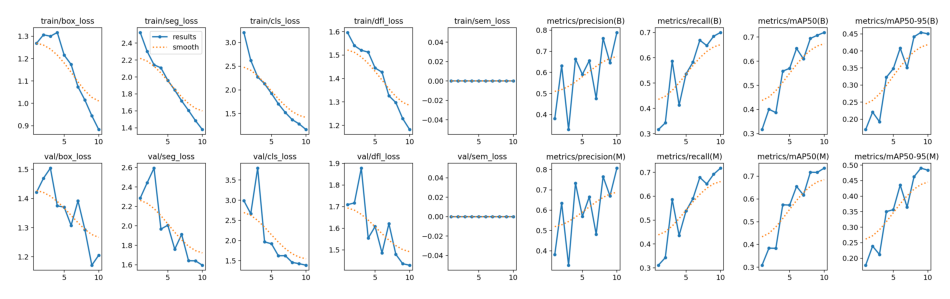

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(
    TRAINING_RESULTS_PLOT
)

plt.figure(figsize=(12,8))
plt.imshow(img)
plt.axis("off")
plt.show()

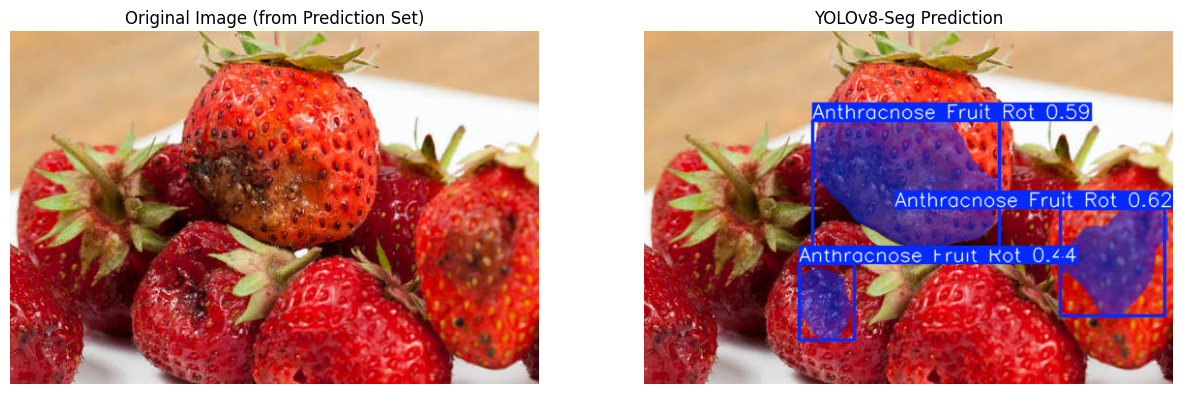

In [ ]:
from PIL import Image
import cv2

# Load the original image that corresponds to the first YOLOv8 prediction result
# results[0].path provides the path to the original image that was processed by results[0]
original_image_for_prediction = Image.open(results[0].path)
img = results[0].plot()

plt.figure(figsize=(15,6))

plt.subplot(1,2,1)
plt.imshow(original_image_for_prediction)
plt.title("Original Image (from Prediction Set)")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("YOLOv8-Seg Prediction")
plt.axis("off")

plt.show()

## Figure 4.4: Sample Fruit Defect Detection Output

Prediction image with bounding boxes.


image 1/1 /content/strawberry.jpeg: 448x640 3 Anthracnose Fruit Rots, 11.5ms
Speed: 2.1ms preprocess, 11.5ms inference, 2.1ms postprocess per image at shape (1, 3, 448, 640)


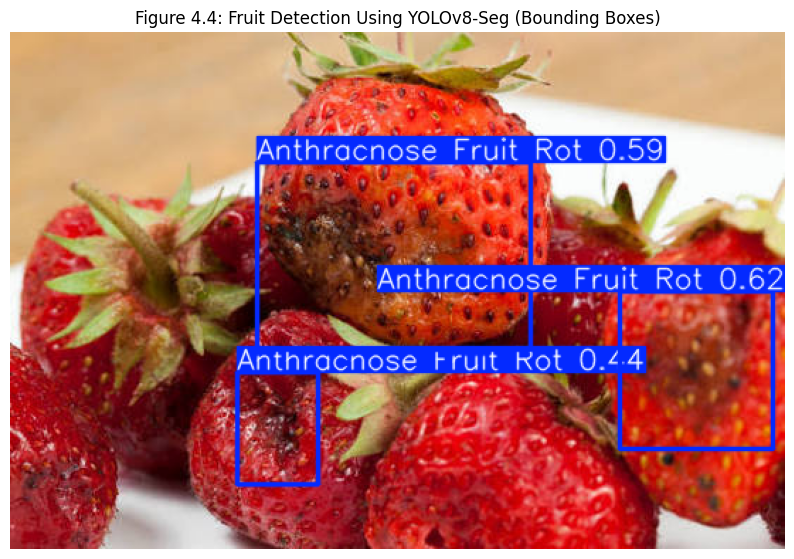

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2

# Load the best trained model
model_fig4_4 = YOLO(BEST_WEIGHTS_PATH)

# Make a prediction on a sample image (e.g., strawberry.jpeg)
results_fig4_4 = model_fig4_4.predict(
    source= SAMPLE_IMAGE_PATH,
    conf=0.25,
    save=False # Do not save the image to disk again
)

# Plot the results with bounding boxes and masks
img_fig4_4 = results_fig4_4[0].plot(boxes=True, masks=False) # Focus on bounding boxes for this figure

plt.figure(figsize=(10,10))
plt.imshow(cv2.cvtColor(img_fig4_4, cv2.COLOR_BGR2RGB))
plt.title("Figure 4.4: Fruit Detection Using YOLOv8-Seg (Bounding Boxes)")
plt.axis("off")
plt.show()

## Figure 4.5: Defect Segmentation Output

Prediction image showing masks.


image 1/1 /content/strawberry.jpeg: 448x640 3 Anthracnose Fruit Rots, 49.7ms
Speed: 6.7ms preprocess, 49.7ms inference, 5.8ms postprocess per image at shape (1, 3, 448, 640)


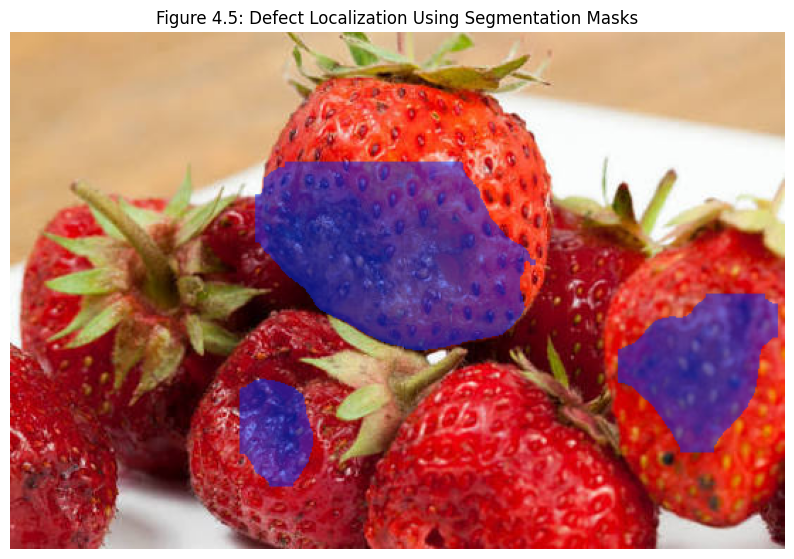

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2

# Load the best trained model
model_fig4_5 = YOLO(BEST_WEIGHTS_PATH)

# Make a prediction on a sample image (e.g., strawberry.jpeg)
results_fig4_5 = model_fig4_5.predict(
    source=SAMPLE_IMAGE_PATH,
    conf=0.25,
    save=False # Do not save the image to disk again
)

# Plot the results, emphasizing segmentation masks
img_fig4_5 = results_fig4_5[0].plot(boxes=False, masks=True) # Focus on masks for this figure

plt.figure(figsize=(10,10))
plt.imshow(cv2.cvtColor(img_fig4_5, cv2.COLOR_BGR2RGB))
plt.title("Figure 4.5: Defect Localization Using Segmentation Masks")
plt.axis("off")
plt.show()

## Figure 4.6: Best Prediction Example

Successful Detection and Segmentation Example.


image 1/1 /content/strawberry.jpeg: 448x640 3 Anthracnose Fruit Rots, 8.5ms
Speed: 2.0ms preprocess, 8.5ms inference, 1.9ms postprocess per image at shape (1, 3, 448, 640)


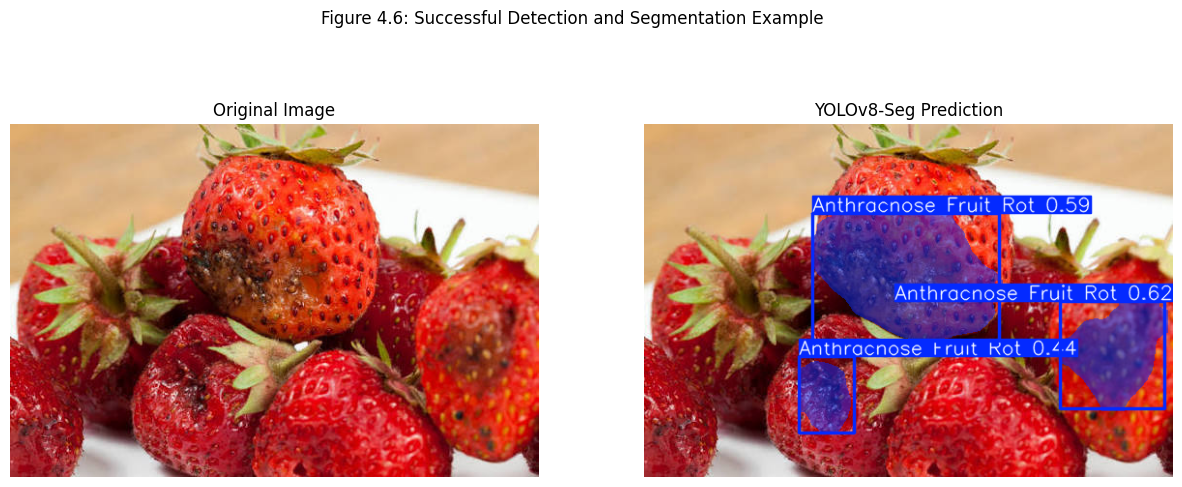

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
from PIL import Image

# Load the best trained model
model_fig4_6 = YOLO(BEST_WEIGHTS_PATH)

# Make a prediction on a sample image (e.g., strawberry.jpeg)
results_fig4_6 = model_fig4_6.predict(
    source=SAMPLE_IMAGE_PATH,
    conf=0.25,
    save=False # Do not save the image to disk again
)

# Get the original image and the plotted prediction
original_image_fig4_6 = Image.open(results_fig4_6[0].path)
predicted_image_fig4_6 = results_fig4_6[0].plot()

plt.figure(figsize=(15,6))

plt.subplot(1,2,1)
plt.imshow(original_image_fig4_6)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(predicted_image_fig4_6, cv2.COLOR_BGR2RGB))
plt.title("YOLOv8-Seg Prediction")
plt.axis("off")

plt.suptitle("Sample Detection and Segmentation Example", y=0.98)
plt.show()

In [ ]:
from ultralytics import YOLO

model = YOLO(BEST_WEIGHTS_PATH)

metrics = model.val(
    data=DATA_YAML_PATH,
    split="test"
)

print("mAP50:", metrics.box.map50)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

Ultralytics 8.4.90 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 86 layers, 3,258,649 parameters, 0 gradients, 11.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1726.3±486.1 MB/s, size: 42.6 KB)
val: Scanning /content/Fruit_detection-1/test/labels.cache... 45 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 45/45 12.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.5s/it 4.4s
                   all         45         71      0.767      0.665      0.736      0.486      0.757      0.655       0.71      0.479
 Anthracnose Fruit Rot          7         12      0.875      0.581      0.721      0.382      0.875      0.582      0.664        0.4
             Gray Mold         28         30      0.822      0.967      0.956        0.7      0.793      0.933       0.93      0.659
  Powdery Mildew Fruit         10       

In [ ]:
print("Segmentation mAP50:", metrics.seg.map50)

Segmentation mAP50: 0.7099036266988582


In [ ]:
import time
import glob

test_images = glob.glob(
    TEST_IMAGES_GLOB
)

start = time.time()

for img in test_images:
    model.predict(
        source=img,
        verbose=False
    )

end = time.time()

avg_time = (end-start)/len(test_images)

fps = 1/avg_time

print(f"Inference Time: {avg_time*1000:.2f} ms/image")
print(f"FPS: {fps:.2f}")

Inference Time: 12.89 ms/image
FPS: 77.55


In [ ]:
import numpy as np

def compute_iou(pred_mask, true_mask):

    intersection = np.logical_and(
        pred_mask,
        true_mask
    ).sum()

    union = np.logical_or(
        pred_mask,
        true_mask
    ).sum()

    return intersection / union

In [ ]:
def compute_dice(pred_mask, true_mask):

    intersection = np.logical_and(
        pred_mask,
        true_mask
    ).sum()

    return (
        2 * intersection
    ) / (
        pred_mask.sum()
        + true_mask.sum()
    )

In [ ]:
import os
import cv2
import numpy as np
from PIL import Image

# Initialize lists to store all individual predicted and ground truth masks
# These will be populated by iterating through test images and their labels
collected_predicted_masks = []
collected_ground_truth_masks = []

# Assuming 'model' and 'test_images' (list of image paths) are available from previous cells.
# Also assuming the dataset structure like /content/Fruit_detection-1/test/images/ and /labels/

dataset_base_path = DATASET_BASE_PATH # Based on prior cells

# Define a fixed target size for all masks based on model training input size (imgsz=1024)
# This ensures all masks (predicted and ground truth) are resized to a consistent dimension.
target_comparison_h, target_comparison_w = 1024, 1024

for img_path in test_images:
    # Get image dimensions to denormalize ground truth coordinates
    with Image.open(img_path) as im:
        original_width, original_height = im.size

    # --- Process Predicted Masks ---
    image_pred_masks = []
    results = model.predict(img_path, verbose=False) # Perform prediction

    if results and results[0].masks is not None:
        # results[0].masks.data contains the tensor of predicted masks, already scaled to model's input size
        # Shape: (num_objects, target_comparison_h, target_comparison_w) is expected here if imgsz=1024
        pred_segmentation_masks_np = results[0].masks.data.cpu().numpy()

        for pred_mask_obj_raw in pred_segmentation_masks_np:
            # Convert to binary mask using a threshold (e.g., 0.5)
            binary_pred_mask_obj = (pred_mask_obj_raw > 0.5).astype(bool)

            # Ensure predicted mask is resized to the target comparison size if it's not already
            if binary_pred_mask_obj.shape[0] != target_comparison_h or binary_pred_mask_obj.shape[1] != target_comparison_w:
                binary_pred_mask_obj = cv2.resize(
                    binary_pred_mask_obj.astype(np.uint8),
                    (target_comparison_w, target_comparison_h),
                    interpolation=cv2.INTER_NEAREST
                ).astype(bool)
            image_pred_masks.append(binary_pred_mask_obj)

    # --- Process Ground Truth Masks ---
    label_path = img_path.replace("/images/", "/labels/").replace(".jpg", ".txt").replace(".jpeg", ".txt")

    image_gt_masks = []
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            lines = f.readlines()

        for line in lines:
            parts = line.strip().split()
            # The first part is class_id, rest are normalized polygon coordinates
            normalized_coords = np.array(parts[1:], dtype=float).reshape(-1, 2)

            # Denormalize coordinates to original image size
            denormalized_points = (normalized_coords * np.array([original_width, original_height])).astype(np.int32)

            # Create an empty binary mask for this ground truth object at original size
            gt_mask_obj_original_size = np.zeros((original_height, original_width), dtype=np.uint8)
            cv2.fillPoly(gt_mask_obj_original_size, [denormalized_points], 1)

            # Resize the ground truth mask to match the fixed target comparison dimensions
            gt_mask_obj_resized = cv2.resize(
                gt_mask_obj_original_size,
                (target_comparison_w, target_comparison_h),
                interpolation=cv2.INTER_NEAREST # Use NEAREST for binary masks
            )
            image_gt_masks.append(gt_mask_obj_resized.astype(bool))

    # Collect all individual masks. Note that the number of predicted and GT masks
    # for an image might differ. The `zip` in the loop below will truncate to the shortest list.
    # The assumption here is that we compare all collected predicted masks against all collected GT masks.
    collected_predicted_masks.extend(image_pred_masks)
    collected_ground_truth_masks.extend(image_gt_masks)

# Now, assign these collected lists to the variables the user's loop expects
predicted_masks = collected_predicted_masks
ground_truth_masks = collected_ground_truth_masks

ious = []
dices = []

for pred_mask, gt_mask in zip(
        predicted_masks,
        ground_truth_masks):

    # Ensure masks are not empty to avoid division by zero or other errors
    # For segmentation, IoU/Dice for two empty masks is often 1.0 (perfect match of nothing).
    # If GT is empty and pred is not, it's a false positive (0.0 score).
    # If GT is not empty and pred is empty, it's a false negative (0.0 score).
    if np.sum(gt_mask) == 0 and np.sum(pred_mask) == 0:
        ious.append(1.0)
        dices.append(1.0)
        continue
    elif np.sum(gt_mask) == 0 and np.sum(pred_mask) > 0:
        ious.append(0.0)
        dices.append(0.0)
        continue
    elif np.sum(gt_mask) > 0 and np.sum(pred_mask) == 0:
        ious.append(0.0)
        dices.append(0.0)
        continue

    # Explicitly check if dimensions match for safety, though they should now be consistent
    if pred_mask.shape != gt_mask.shape:
        # This warning should ideally not occur with the fix above
        print(f"Warning: Mask shapes mismatch: pred_mask {pred_mask.shape}, gt_mask {gt_mask.shape}. Skipping comparison.")
        continue

    ious.append(
        compute_iou(
            pred_mask,
            gt_mask
        )
    )

    dices.append(
        compute_dice(
            pred_mask,
            gt_mask
        )
    )

# Check if ious and dices lists are empty before computing mean
if ious:
    print("Mean IoU:", np.mean(ious))
else:
    print("No valid IoU comparisons were made.")

if dices:
    print("Mean Dice:", np.mean(dices))
else:
    print("No valid Dice comparisons were made.")

Mean IoU: 0.0988166391889861
Mean Dice: 0.13546192401214016


## Evaluation Metrics on Test Dataset

In [ ]:
import numpy as np

# Retrieve metrics from the last validation run (from cell 'qmpK_SbnxLlN')
# metrics object contains both box and segmentation metrics
# Precision and Recall are available from the metrics object
print(f"Segmentation Precision: {metrics.seg.mp:.4f}")
print(f"Segmentation Recall: {metrics.seg.mr:.4f}")

# Calculate Pixel Accuracy
# We need to ensure that `ground_truth_masks` and `predicted_masks` are populated from cell 'wep_XnRQ4URb'
# Pixel accuracy: (True Positives + True Negatives) / Total Pixels

correct_pixels = 0
total_pixels = 0

for pred_mask, gt_mask in zip(predicted_masks, ground_truth_masks):
    if pred_mask.shape != gt_mask.shape:
        # This should ideally not happen if previous steps correctly resized masks
        continue

    # Count true positives (pixels correctly predicted as foreground)
    tp = np.logical_and(pred_mask, gt_mask).sum()
    # Count true negatives (pixels correctly predicted as background)
    tn = np.logical_and(~pred_mask, ~gt_mask).sum()

    correct_pixels += tp + tn
    total_pixels += pred_mask.size # pred_mask.size is total pixels in one mask

if total_pixels > 0:
    pixel_accuracy = correct_pixels / total_pixels
    print(f"Pixel Accuracy: {pixel_accuracy:.4f}")
else:
    print("Could not calculate pixel accuracy: No masks processed or total_pixels is zero.")

# Print Mean IoU and Mean Dice (already computed in cell 'wep_XnRQ4URb')
if ious:
    print(f"Mean IoU: {np.mean(ious):.4f}")
else:
    print("Mean IoU: Not available (no valid IoU comparisons were made).")

if dices:
    print(f"Mean Dice Score: {np.mean(dices):.4f}")
else:
    print("Mean Dice Score: Not available (no valid Dice comparisons were made).")

# Print Inference Time and FPS (already computed in cell 'asnnWpfo4Mdw')
print(f"Inference Time: {avg_time*1000:.2f} ms/image")
print(f"FPS: {fps:.2f}")

Segmentation Precision: 0.7569
Segmentation Recall: 0.6546
Pixel Accuracy: 0.8753
Mean IoU: 0.0988
Mean Dice Score: 0.1355
Inference Time: 12.89 ms/image
FPS: 77.55
